# 02 - Data quality audit

Goal: find what is wrong or odd in the event log, count how many incidents each problem touches, and decide what to do about it. I also check how stable each column is inside an incident, because it is the base for rebuilding one row per incident later. Nothing is removed in this notebook.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # to import src from the notebooks folder

import pandas as pd
from src import config, data_loading as dl, audit as au, plots as pl

pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 70, "display.max_rows", 100)
ID = config.ID_COL
df = dl.load_raw()
print("rows:", len(df), "| columns:", df.shape[1], "| incidents:", df[ID].nunique())

rows: 141712 | columns: 36 | incidents: 24918


## 1. Granularity

In [2]:
events = au.events_per_incident(df)
display(events.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2).to_frame("events per incident").T)
print("incidents with a single event:", int((events == 1).sum()))
print("incidents with 2 events:", int((events == 2).sum()))

long_threshold = events.quantile(0.99)
long_inc = events[events > long_threshold]
print(f"\n99th percentile = {long_threshold:.0f} events -> {len(long_inc)} incidents above it ({len(long_inc) / len(events):.1%})")
events.sort_values(ascending=False).head(5).to_frame("n_events")

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
events per incident,24918.0,5.69,3.68,2.0,3.0,5.0,7.0,10.0,13.0,19.0,58.0


incidents with a single event: 0
incidents with 2 events: 1806

99th percentile = 19 events -> 213 incidents above it (0.9%)


,n_events
number,
INC0019396,58
INC0044260,56
INC0005927,46
INC0020718,45
INC0011206,44


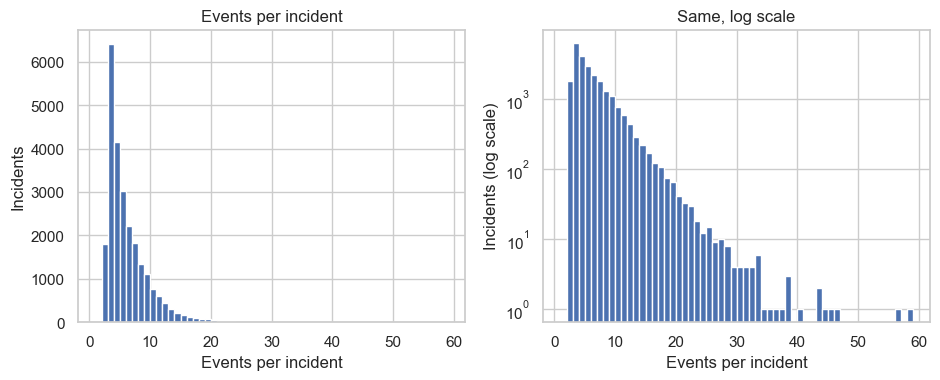

In [3]:
pl.plot_events_per_incident(events);

There are 24,918 incidents with 5.69 events on average (median 5, min 2, max 58). No incident has a single event and 1,806 have only 2. The distribution is skewed to the right: 213 incidents (0.9%) are above the 99th percentile of 19 events, and the longest one (`INC0019396`) has 58.

The unit of the project is the incident, not the row. Long histories are not errors (a hard incident gets more updates), so I keep them.

## 2. Exact duplicates

In [4]:
n_dup, dup_rows = au.exact_duplicates(df)
print("fully identical rows:", n_dup)

# same content once the columns of the update itself are ignored
event_meta = ["sys_mod_count", "sys_updated_at", "sys_updated_by"]
same_content = df.duplicated(subset=[c for c in df.columns if c not in event_meta])
print("events with the same content as an earlier event of the file (ignoring update counter, time, author):", int(same_content.sum()))
print("incidents concerned:", df.loc[same_content, ID].nunique())

fully identical rows: 0
events with the same content as an earlier event of the file (ignoring update counter, time, author): 29223
incidents concerned: 12039


No row is exactly duplicated. If I ignore the update counter, the time and the author, 29,223 events (in 12,039 incidents) have the same content as an earlier event. They are not real duplicates, because the time and the counter are different. They are probably updates where a field that is not in the file changed, but I can't check it.

Decision: keep everything.

## 3. Missing values

In [5]:
raw = dl.read_raw_text()
q_marks = (raw == "?").sum()
print("'?' in raw file == NaN after loading, for every column:", bool((q_marks.values == df.isna().sum().values).all()))

miss = au.missing_summary(df)
miss[miss["n_missing"] > 0]

'?' in raw file == NaN after loading, for every column: True


,dtype,n_missing,pct_missing,n_unique
caused_by,object,141689,99.98,3
vendor,object,141468,99.83,4
cmdb_ci,object,141267,99.69,50
rfc,object,140721,99.30,181
problem_id,object,139417,98.38,252
sys_created_by,object,53076,37.45,185
sys_created_at,datetime64[ns],53076,37.45,11552
u_symptom,object,32964,23.26,525
assigned_to,object,27496,19.40,234
assignment_group,object,14213,10.03,78


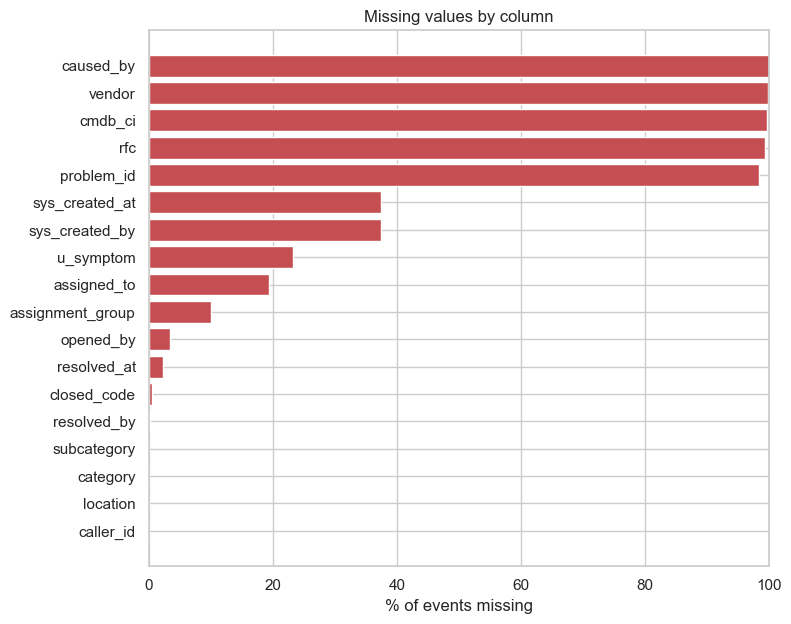

In [6]:
pl.plot_missing(miss);

In [7]:
inc_missing = au.incident_level_missing(df)
inc_missing.loc[miss[miss["n_missing"] > 0].index].sort_values("pct_incidents_all_events_missing", ascending=False)

,pct_incidents_all_events_missing,pct_incidents_some_events_missing
caused_by,99.99,99.99
cmdb_ci,99.78,99.80
vendor,99.73,99.94
rfc,99.28,99.61
problem_id,98.47,99.04
sys_created_by,46.13,46.13
sys_created_at,46.13,46.13
u_symptom,22.12,24.58
resolved_at,6.24,6.24
opened_by,2.87,2.87


In [8]:
# is a missing value linked to the state of the event? (assigned_to by state)
(df.groupby("incident_state")["assigned_to"].apply(lambda s: s.isna().mean() * 100).round(1)
   .to_frame("% assigned_to missing"))

,% assigned_to missing
incident_state,
-100,0.0
Active,21.8
Awaiting Evidence,13.2
Awaiting Problem,17.1
Awaiting User Info,26.3
Awaiting Vendor,7.8
Closed,2.9
New,37.3
Resolved,2.9


The `?` is the only missing marker, and after loading the number of NaN equals the number of `?` in every column.

What I see:
- `caused_by`, `vendor`, `cmdb_ci`, `rfc` and `problem_id` are missing in more than 98% of the events. Here `?` means "nothing linked" more than "lost value". They are almost empty, so they will not help a model.
- `sys_created_by` and `sys_created_at` are missing in 37.5% of the events, and on **all** events for 46.1% of the incidents. So it is a property of the incident, not of the event. I don't know why.
- `u_symptom` is similar: 23.3% of the events, and no symptom on any event for 22.1% of the incidents. "No symptom" may carry information.
- `assigned_to` is empty more often at the start (37.3% of `New` events, 21.8% of `Active`) than at the end (2.9% of `Closed`). It is filled while the incident is handled.
- `resolved_at` is missing in 2.2% of the events, but on all events for 6.24% of the incidents. This is the important one, see the Resolution section.

Decision: no value is removed or imputed here. For categorical columns a missing value can become its own level later, inside the pipeline.

## 4. Data types

In [9]:
print(df.dtypes.astype(str).value_counts().to_string())
print("\nboolean columns, % True:")
print((df[config.BOOL_COLS].mean() * 100).round(1).to_string())
for c in ["incident_state", "contact_type", "impact", "urgency", "priority", "notify", "closed_code"]:
    print(f"\n{c}:")
    print(df[c].value_counts(dropna=False).to_string())

object            24
datetime64[ns]     5
bool               4
int64              3

boolean columns, % True:
active                     82.4
made_sla                   93.5
knowledge                  17.9
u_priority_confirmation    28.9

incident_state:
incident_state
Active                38716
New                   36407
Resolved              25751
Closed                24985
Awaiting User Info    14642
Awaiting Vendor         707
Awaiting Problem        461
Awaiting Evidence        38
-100                      5

contact_type:
contact_type
Phone             140462
Self service         995
Email                220
IVR                   18
Direct opening        17

impact:
impact
2 - Medium    134335
3 - Low         3886
1 - High        3491

urgency:
urgency
2 - Medium    134094
1 - High        4020
3 - Low         3598

priority:
priority
3 - Moderate    132452
4 - Low           4030
2 - High          2972
1 - Critical      2258

notify:
notify
Do Not Notify    141593
Send Email   

In [10]:
# links between categorical columns
print("distinct priority values for each (impact, urgency) pair, max:", df.groupby(["impact", "urgency"])["priority"].nunique().max())
print("contact_type == Email exactly when notify == Send Email:", bool((df["contact_type"].eq("Email") == df["notify"].eq("Send Email")).all()))

distinct priority values for each (impact, urgency) pair, max: 1
contact_type == Email exactly when notify == Send Email: False


Types are as expected: 24 text columns (all anonymised labels, there is no real numeric measure), 5 dates, 4 booleans and 3 counters. Booleans: `active` is True on 82.4% of the events, `made_sla` on 93.5%, `knowledge` on 17.9% and `u_priority_confirmation` on 28.9%.

What I see in the categorical columns:
- `incident_state` has a strange value, `-100` (5 events, 2 incidents), next to the 8 real states. It looks like a wrong label. I keep these 2 incidents for now and will check them in notebook 03.
- `priority` is fully given by `impact` and `urgency` (one priority for each pair). Almost all events are `2 - Medium` for both (134,335 events for impact, 134,094 for urgency, about 95%), so these columns vary little.
- `contact_type` is `Phone` for 140,462 events (99.1%). The other values are `Self service` (995), `Email` (220), `IVR` (18) and `Direct opening` (17). `notify` is `Send Email` on only 119 events, and the check shows it is not the same thing as `contact_type == Email` (220 events). I will compare them again in the EDA.
- `closed_code` has 17 codes and 714 missing values.

The impact, urgency and priority labels look like `1 - High`, so they can be turned into ordered numbers later.

## 5. Dates: conversion, range, extreme values

In [11]:
# load_raw stops with an error if a date does not match the format, so there is no invalid date here
print("missing values:", df[config.DATE_COLS].isna().sum().to_dict())
au.date_ranges(df)

missing values: {'opened_at': 0, 'sys_created_at': 53076, 'sys_updated_at': 0, 'resolved_at': 3141, 'closed_at': 0}


,min,max
opened_at,2016-02-29 01:16:00,2017-02-16 14:17:00
sys_created_at,2016-02-29 01:23:00,2017-01-27 16:59:00
sys_updated_at,2016-02-29 01:23:00,2017-02-18 15:00:00
resolved_at,2016-02-29 09:04:00,2017-02-17 00:47:00
closed_at,2016-02-29 17:47:00,2017-02-18 15:00:00


In [12]:
inc = au.resolution_diagnostic(df)
span_days = (inc["closed_at"] - inc["opened_at"]).dt.total_seconds() / 86400
display(span_days.describe(percentiles=[.5, .9, .99]).round(1).to_frame("opening to closing (days)").T)
print("incidents open for more than 180 days:", int((span_days > 180).sum()), f"({(span_days > 180).mean():.2%})")
print("incidents open for more than 365 days:", int((span_days > 365).sum()))

,count,mean,std,min,50%,90%,99%,max
opening to closing (days),24918.0,13.1,22.2,0.0,6.1,22.2,121.9,341.3


incidents open for more than 180 days: 125 (0.50%)
incidents open for more than 365 days: 0


All the dates match the format, so there is no invalid date. Only `sys_created_at` (53,076 events) and `resolved_at` (3,141 events) have missing values.

Incidents are opened between 29 Feb 2016 and 16 Feb 2017. From opening to closing, the median is 6.1 days, 90% of the incidents are under 22.2 days, the 99th percentile is 121.9 days and the maximum is 341.3 days. 125 incidents (0.50%) stay open more than 180 days, none more than 365. They look like real slow cases and not date errors, so I keep them. They will make the target very skewed.

## 6. Date consistency

In [13]:
pairs = [
    ("opened_at", "resolved_at"), ("opened_at", "closed_at"), ("resolved_at", "closed_at"),
    ("sys_created_at", "sys_updated_at"), ("opened_at", "sys_created_at"),
    ("opened_at", "sys_updated_at"), ("sys_updated_at", "closed_at"),
]
date_checks = au.date_pair_violations(df, pairs)
date_checks

,check,rows_compared,n_events,n_incidents,pct_incidents
0,opened_at > resolved_at,138571,0,0,0.000
1,opened_at > closed_at,141712,0,0,0.000
2,resolved_at > closed_at,138571,0,0,0.000
3,sys_created_at > sys_updated_at,88636,0,0,0.000
4,opened_at > sys_created_at,88636,34,6,0.024
5,opened_at > sys_updated_at,141712,5,5,0.020
6,sys_updated_at > closed_at,141712,0,0,0.000


In [14]:
# size of the two small problems above
late_created = df[df["opened_at"] > df["sys_created_at"]]
print("opened_at after sys_created_at: gap in hours")
print(((late_created["opened_at"] - late_created["sys_created_at"]).dt.total_seconds() / 3600).describe().round(2).to_string())
late_update = df[df["opened_at"] > df["sys_updated_at"]]
print("\nopened_at after sys_updated_at: gap in hours")
print(((late_update["opened_at"] - late_update["sys_updated_at"]).dt.total_seconds() / 3600).describe().round(2).to_string())

# time between opening and the first event
first, _ = au.first_last_events(df)
lag_h = (first["sys_updated_at"] - first["opened_at"]).dt.total_seconds() / 3600
print("\nfirst logged event minus opened_at, in hours:")
print(lag_h.describe(percentiles=[.5, .9, .99]).round(2).to_string())

opened_at after sys_created_at: gap in hours
count    34.00
mean      1.95
std       0.37
min       1.48
25%       1.50
50%       1.98
75%       2.40
max       2.45

opened_at after sys_updated_at: gap in hours
count    5.00
mean     1.64
std      0.85
min      0.30
25%      1.42
50%      1.82
75%      2.23
max      2.45

first logged event minus opened_at, in hours:
count    24918.00
mean         0.09
std          0.23
min         -2.45
50%          0.02
90%          0.22
99%          0.82
max         19.10


In [15]:
# odd cases in the event order
orders = au.file_order_checks(df)
print({k: v for k, v in orders.items() if k.startswith("incidents")})
odd_ids = df.groupby(ID, sort=False)["sys_mod_count"].apply(lambda s: not s.is_monotonic_increasing)
example = odd_ids[odd_ids].index[0]
df.loc[df[ID] == example, ["number", "incident_state", "sys_mod_count", "sys_updated_at"]]

{'incidents where sys_updated_at goes backwards': 1, 'incidents where sys_mod_count is not increasing': 4, 'incidents with a repeated sys_mod_count': 5, 'incidents whose first event has sys_mod_count != 0': 5}


,number,incident_state,sys_mod_count,sys_updated_at
328,INC0000130,New,2,2016-02-29 07:27:00
329,INC0000130,New,1,2016-02-29 09:59:00
330,INC0000130,Active,2,2016-03-01 14:13:00
331,INC0000130,Active,3,2016-03-03 10:16:00
332,INC0000130,Resolved,4,2016-03-03 10:16:00
333,INC0000130,Closed,5,2016-03-08 11:00:00


The main order of the dates is clean: no incident with a resolution before the opening, none with a closure before the resolution, none with an update after the closure, and `sys_created_at` is never after `sys_updated_at`.

Two small problems:
- `opened_at` is later than `sys_created_at` on 34 events (6 incidents), with a gap of 1.48 to 2.45 hours. It is also later than `sys_updated_at` on 5 events (5 incidents), with a gap of 0.3 to 2.45 hours. Maybe a clock or time zone shift, I'm not sure. It is small, so I keep it.
- The first logged event comes a median of 0.02 hours (about 1 minute) after the opening, 99% of them within 0.82 hours, and the maximum is 19.1 hours. So the first event is close to the opening.

About the event order: `sys_updated_at` goes backwards in 1 incident, and `sys_mod_count` is not increasing in 4 incidents (repeated in 5). In `INC0000130` for example the counter reads 2 then 1 while the times are fine. It concerns only a handful of incidents.

Decision: order the events with `sys_updated_at`, then the file order, and don't use `sys_mod_count` for the order.

## 7. Stability of each column inside an incident

In [16]:
stab = au.column_stability(df)
stab

,pct_any_change,pct_value_change,pct_missing_first,pct_missing_last,n_incidents_changing
opened_by,0.00,0.00,2.87,2.87,0
sys_created_at,0.00,0.00,46.13,46.13,0
sys_created_by,0.00,0.00,46.13,46.13,0
opened_at,0.00,0.00,0.00,0.00,0
caused_by,0.00,0.00,99.99,99.99,1
notify,0.00,0.00,0.00,0.00,0
closed_code,0.00,0.00,0.43,0.43,0
resolved_by,0.00,0.00,0.40,0.40,0
resolved_at,0.00,0.00,6.24,6.24,0
closed_at,0.00,0.00,0.00,0.00,0


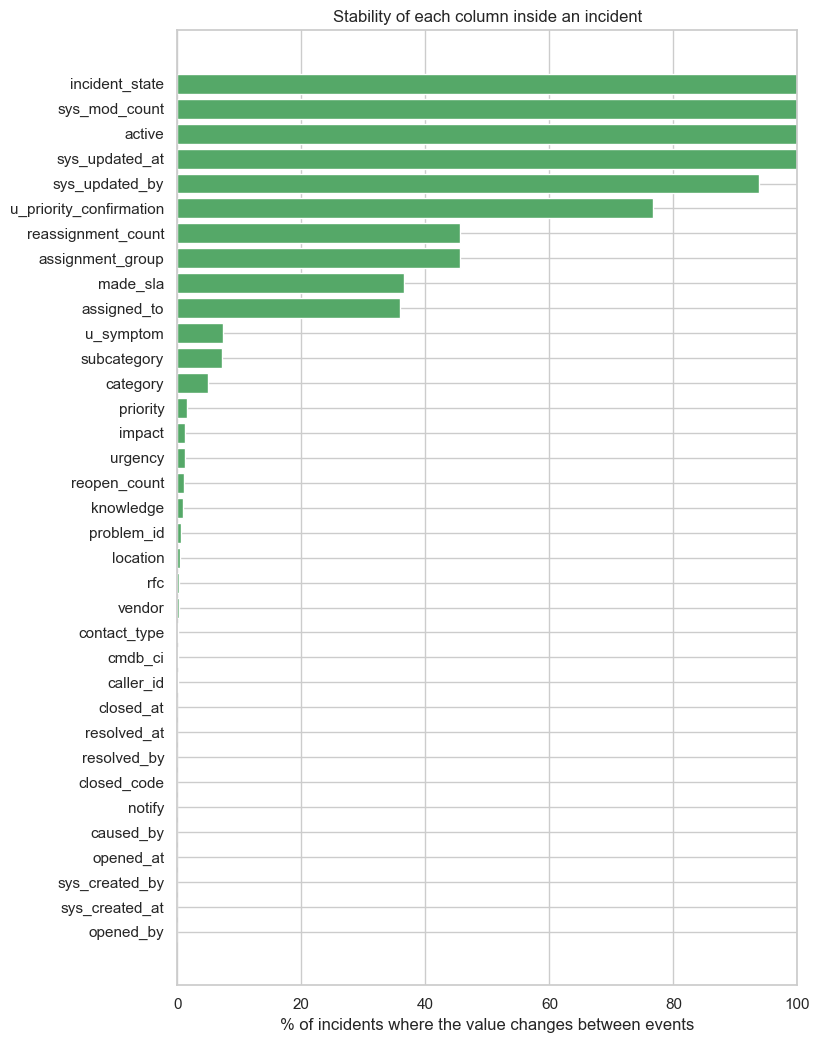

In [17]:
pl.plot_stability(stab);

In [18]:
groups = pd.cut(stab["pct_any_change"], [-0.01, 0.1, 5, 50, 100], labels=["constant (<=0.1%)", "almost stable (0.1-5%)", "changes sometimes (5-50%)", "changes often (>50%)"])
groups.value_counts().sort_index().to_frame("n_columns")

,n_columns
pct_any_change,
constant (<=0.1%),13
almost stable (0.1-5%),10
changes sometimes (5-50%),6
changes often (>50%),6


How to read it: `pct_any_change` is the share of incidents where the column does not have the same value on every event.

- **Constant** (13 columns): `opened_at`, `opened_by`, `contact_type`, `notify`, `caller_id`, but also `resolved_at`, `closed_at`, `closed_code`, `resolved_by` and `sys_created_*`. Constant does not mean known at opening: the closure fields are copied on all events from the start.
- **Classification**: `category` (4.9%), `subcategory` (7.2%) and `u_symptom` (7.4%) change in a small share of incidents. `impact`, `urgency` and `priority` change in 1.2% to 1.5%. For these, the value at opening can differ from the final value, so I need a rule for the "initial value" in notebook 03.
- **Changes a lot**: `u_priority_confirmation` (76.8%), `sys_updated_by` (93.8%), `incident_state`, `active`, `sys_mod_count` and `sys_updated_at` (about 100%). These follow the life of the incident.
- **In between**: `reassignment_count` (45.6%), `assignment_group` (45.5%), `made_sla` (36.6%), `assigned_to` (35.9%).
- `assigned_to` changes in 35.9% of the incidents, but only 11.5% change between two real values, the others go from empty to filled.
- `assignment_group` is missing on 3.6% of the first events and 8.7% of the last events, so the last row is not a safe "final value" either.

For the incident table this means: no first row, no last row, one rule per column.

## 8. Resolution

In [19]:
no_res = ~inc["has_resolved_at"]
print("incidents:", len(inc))
print("with resolved_at:", int(inc["has_resolved_at"].sum()))
print(f"without resolved_at: {int(no_res.sum())} ({no_res.mean():.2%})")
print("\ndistinct resolved_at values per incident:")
print(inc["n_distinct_resolved_at"].value_counts().sort_index().to_string())

incidents: 24918
with resolved_at: 23362
without resolved_at: 1556 (6.24%)

distinct resolved_at values per incident:
n_distinct_resolved_at
0     1556
1    23362


In [20]:
# reopenings
reopened = inc["max_reopen_count"] > 0
several_phases = inc["n_resolved_phases"] > 1
print("incidents with reopen_count > 0:", int(reopened.sum()))
print("incidents with more than one 'Resolved' phase:", int(several_phases.sum()))
print("both at once:", int((reopened & several_phases).sum()))
print("\nnumber of 'Resolved' phases per incident:")
print(inc["n_resolved_phases"].value_counts().sort_index().to_string())

# is resolved_at the time of the last 'Resolved' event?
both = inc["has_resolved_at"] & inc["has_resolved_state"]
same = (inc.loc[both, "resolved_at"] == inc.loc[both, "last_resolved_event_at"])
print(f"\nincidents with resolved_at and a 'Resolved' event: {int(both.sum())}")
print(f"resolved_at equals the time of the last 'Resolved' event: {int(same.sum())} ({same.mean():.2%})")

incidents with reopen_count > 0: 275
incidents with more than one 'Resolved' phase: 275
both at once: 275

number of 'Resolved' phases per incident:
n_resolved_phases
0       13
1    24630
2      245
3       19
4        4
5        4
7        2
9        1

incidents with resolved_at and a 'Resolved' event: 23362
resolved_at equals the time of the last 'Resolved' event: 23362 (100.00%)


without resolved_at, and with a 'Resolved' event: 1543
without resolved_at, and never 'Resolved': 13

state of the FIRST logged event:
has_resolved_at     has resolved_at  no resolved_at
first_event_state                                  
Active                         6503               0
Awaiting Problem                  6               0
Awaiting User Info              193               0
New                           16384              13
Resolved                        276            1543


,n_incidents,n_with_resolved_at,pct_missing
final_priority,,,
1 - Critical,270,270,0.00
2 - High,408,408,0.00
3 - Moderate,23466,22010,6.20
4 - Low,774,674,12.92


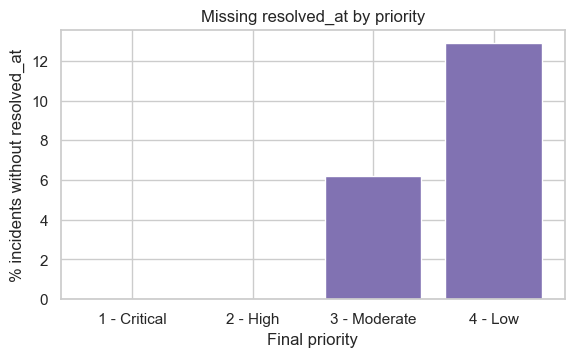

In [21]:
# incidents without resolved_at
print("without resolved_at, and with a 'Resolved' event:", int((no_res & inc["has_resolved_state"]).sum()))
print("without resolved_at, and never 'Resolved':", int((no_res & ~inc["has_resolved_state"]).sum()))

print("\nstate of the FIRST logged event:")
print(pd.crosstab(inc["first_event_state"], inc["has_resolved_at"].map({True: "has resolved_at", False: "no resolved_at"})).to_string())

prio = inc.groupby("final_priority")["has_resolved_at"].agg(n_incidents="size", n_with_resolved_at="sum")
prio["pct_missing"] = ((1 - prio["n_with_resolved_at"] / prio["n_incidents"]) * 100).round(2)
display(prio)
pl.plot_missing_resolution_by_priority(prio);

In [22]:
hours = lambda s: s.dt.total_seconds() / 3600
with_res = inc[inc["has_resolved_at"]]
recov = inc[no_res & inc["has_resolved_state"]]
cmp = pd.DataFrame({
    "resolved_at - opened_at (incidents with resolved_at)": hours(with_res["resolved_at"] - with_res["opened_at"]).describe(percentiles=[.5, .9]),
    "last Resolved event - opened_at (incidents without resolved_at)": hours(recov["last_resolved_event_at"] - recov["opened_at"]).describe(percentiles=[.5, .9]),
    "closed_at - resolved_at (with resolved_at)": hours(with_res["closed_at"] - with_res["resolved_at"]).describe(percentiles=[.5, .9]),
    "closed_at - last Resolved event (without resolved_at)": hours(recov["closed_at"] - recov["last_resolved_event_at"]).describe(percentiles=[.5, .9]),
}).round(1)
display(cmp.T)
dur = hours(with_res["resolved_at"] - with_res["opened_at"])
print("incidents with resolved_at and a duration under 1 hour:", int((dur < 1).sum()), f"({(dur < 1).mean():.1%})")
print("duration of exactly 0:", int((dur == 0).sum()))
print("duration quantiles (hours):", dur.quantile([.5, .9, .99]).round(1).to_dict(), "| max:", round(dur.max(), 1))

,count,mean,std,min,50%,90%,max
resolved_at - opened_at (incidents with resolved_at),23362.0,178.2,532.8,0.0,22.1,381.5,8070.2
last Resolved event - opened_at (incidents without resolved_at),1543.0,2.4,35.5,0.0,0.0,0.0,600.0
closed_at - resolved_at (with resolved_at),23362.0,147.2,143.9,0.0,120.6,177.5,5851.6
closed_at - last Resolved event (without resolved_at),1543.0,163.7,149.7,113.8,120.8,248.2,1730.2


incidents with resolved_at and a duration under 1 hour: 7503 (32.1%)
duration of exactly 0: 39
duration quantiles (hours): {0.5: 22.1, 0.9: 381.5, 0.99: 2843.4} | max: 8070.2


**What the data shows**
- 23,362 incidents have a `resolved_at` and 1,556 (6.24%) do not. No incident has two different `resolved_at` values, even the reopened ones.
- 275 incidents were reopened (`reopen_count > 0`). They are exactly the 275 incidents with more than one `Resolved` phase. For all 23,362 incidents that have both, `resolved_at` is the time of the **last** `Resolved` event (100%). So the column keeps only the last resolution. The earlier resolutions of the reopened incidents are only visible in the events.
- Of the 1,556 incidents without `resolved_at`, 1,543 have a `Resolved` event and 13 never reach `Resolved`.
- All the 1,543 start with `Resolved` as first logged event. In total 1,819 incidents are created already `Resolved`: 1,543 without `resolved_at` and 276 with it. For the 1,543, the time from opening to the `Resolved` event has a median of 0 hours (90th percentile 0, max 600). So they are not random missing values: they look like incidents logged after the work was done, where the system never filled `resolved_at`. This is my reading, not a certain fact.
- The missing share depends on the priority: 0% for Critical and High, 6.20% for Moderate and 12.92% for Low.
- For the 23,362 other incidents, the duration (`resolved_at - opened_at`) has a median of 22.1 hours, a 90th percentile of 381.5, a 99th of 2,843.4 and a max of 8,070.2 hours. 7,503 incidents (32.1%) are resolved in under 1 hour, and 39 in exactly 0.
- `closed_at` comes a median of 120.6 hours (5 days) after `resolved_at`. For the 1,543 the median is 120.8 and the minimum 113.8. It looks like an automatic closing delay.

**What it means for the target (recommendation, not final)**
1. Main target: last resolution time minus `opened_at`, in hours. The resolution time is `resolved_at`, or the time of the last `Resolved` event when `resolved_at` is missing. This rule gives the same value as `resolved_at` for 100% of the 23,362 incidents that have both, so it is safe for the 1,543 others.
2. These 1,543 form a separate group with durations close to 0. Dropping them would remove 6.2% of the incidents, almost all of the instant ones, and would bias the sample. Keeping them adds a spike at 0 and a group of incidents already resolved when they are opened. To decide in notebook 03 (I would compare with and without them, with a flag).
3. Don't use `closed_at - opened_at` as the main target: it is mostly the fixed 5-day delay after the resolution. It can stay as an optional second target.
4. The 275 reopened incidents (1.1%) are kept and flagged. Their target includes the time of the reopening.
5. The 13 incidents that never reach `Resolved` (0.05%) have no target and would be excluded from the supervised set only.

## 9. Unusual numeric values and rare categories

In [23]:
per_inc = df.groupby(ID, sort=False)[config.INT_COLS].max()
display(per_inc.describe(percentiles=[.5, .99]).round(2))
print("reassignment_count (max per incident), value counts of the top values:")
print(per_inc["reassignment_count"].value_counts().sort_index().tail(8).to_string())
print("\nincidents whose last sys_mod_count is >= number of logged events:", int((per_inc["sys_mod_count"] >= events).sum()),
      f"({(per_inc['sys_mod_count'] >= events).mean():.1%})")

,reassignment_count,reopen_count,sys_mod_count
count,24918.00,24918.00,24918.00
mean,0.94,0.01,6.68
std,1.57,0.15,8.55
min,0.00,0.00,1.00
50%,0.00,0.00,4.00
99%,7.00,1.00,46.00
max,27.00,8.00,129.00


reassignment_count (max per incident), value counts of the top values:
reassignment_count
14    5
15    3
16    1
17    1
18    2
20    3
22    1
27    1

incidents whose last sys_mod_count is >= number of logged events: 9254 (37.1%)


In [24]:
MIN_INCIDENTS = 5   # a value is rare if it appears in fewer incidents than this
cols = ["caller_id", "opened_by", "location", "category", "subcategory", "u_symptom", "assignment_group", "assigned_to", "resolved_by", "closed_code", "incident_state"]
au.cardinality_table(df, cols, MIN_INCIDENTS)

,n_unique,n_rare_values,incidents_with_rare_value
column,,,
caller_id,5244,3486,7119
opened_by,207,90,167
location,224,99,175
category,58,12,16
subcategory,254,89,164
u_symptom,525,300,513
assignment_group,78,10,14
assigned_to,234,56,125
resolved_by,216,51,120


In [25]:
print("rare values of category:")
display(au.rare_categories(df, "category", MIN_INCIDENTS))
print("rare values of incident_state:")
au.rare_categories(df, "incident_state", MIN_INCIDENTS)

rare values of category:


,n_events,n_incidents
category,,
Category 12,3,1
Category 14,5,1
Category 15,3,1
Category 27,2,1
Category 3,1,1
Category 36,2,1
Category 49,2,1
Category 48,10,1
Category 58,5,1


rare values of incident_state:


,n_events,n_incidents
incident_state,,
-100,5,2


**Numbers.** `reassignment_count` has a 99th percentile of 7 and a max of 27 (1 incident). `reopen_count` goes up to 8. `sys_mod_count` reaches 129 for one incident while the longest incident has 58 events. For 9,254 incidents (37.1%) the highest `sys_mod_count` is at least the number of logged events, so some updates are probably not in the log. I treat these as real values, not errors, and I keep them.

**Rare categories** (a value in fewer than 5 incidents, a threshold I chose only for this audit):
- `caller_id`: 3,486 of 5,244 values are rare, and they touch 7,119 incidents (29%). Too sparse for one-hot encoding.
- `u_symptom`: 300 of 525 values. `location`: 99 of 224. `subcategory`: 89 of 254. `opened_by`: 90 of 207. `assigned_to`: 56 of 234. `resolved_by`: 51 of 216.
- `category`: 12 of 58 values, but they touch only 16 incidents. `assignment_group`: 10 of 78 values, 14 incidents.
- `incident_state`: the only rare value is the strange `-100`.

High-cardinality columns will need grouping of the rare values (fitted on the train set only, inside the pipeline) or exclusion. I will decide later.

## 10. Impact of each problem

In [26]:
n = df[ID].nunique()
miss_inc = df.drop(columns=ID).isna().groupby(df[ID], sort=False).all()
ever_filled = lambda col: int((~df[col].isna()).groupby(df[ID]).any().sum())
rows = [
    ("Exact duplicate rows", dup_rows[ID].nunique(), "None found, nothing to remove."),
    ("Incident not ending in state Closed", int((inc["last_event_state"] != "Closed").sum()), "None found."),
    ("No resolved_at", int(no_res.sum()), "Keep. Target rule decided in notebook 03."),
    ("  of which never in state Resolved", int((no_res & ~inc["has_resolved_state"]).sum()), "No resolution time possible. Counted, excluded later."),
    ("Reopened at least once (reopen_count > 0)", int(reopened.sum()), "Keep, flag. resolved_at is the last resolution."),
    ("First logged event is not 'New'", int((inc["first_event_state"] != "New").sum()), "First row is not the opening state. Rule needed in notebook 03."),
    ("First logged event already 'Resolved'", int((inc["first_event_state"] == "Resolved").sum()), "Created already resolved. To study in notebook 03."),
    ("Resolved in less than 1 hour (with resolved_at)", int((dur < 1).sum()), "Not an error. Keep, look at it in the EDA."),
    ("Open more than 180 days (opening to closing)", int((span_days > 180).sum()), "Not an error by default. Keep."),
    ("sys_created_at / sys_created_by missing on all events", int(miss_inc["sys_created_at"].sum()), "Keep as missing. Unclear cause."),
    ("opened_by missing on all events", int(miss_inc["opened_by"].sum()), "Keep as missing."),
    ("u_symptom missing on all events", int(miss_inc["u_symptom"].sum()), "Keep as missing (maybe its own category)."),
    ("cmdb_ci filled at least once", ever_filled("cmdb_ci"), "Almost always missing, probably dropped."),
    ("problem_id filled at least once", ever_filled("problem_id"), "Linked after opening, excluded anyway."),
    ("opened_at later than sys_created_at", int(date_checks.loc[date_checks["check"] == "opened_at > sys_created_at", "n_incidents"].iloc[0]), "Small timing gap. Keep."),
    ("opened_at later than sys_updated_at", int(date_checks.loc[date_checks["check"] == "opened_at > sys_updated_at", "n_incidents"].iloc[0]), "Small timing gap. Keep."),
    ("sys_mod_count not increasing or repeated", int(max(orders["incidents where sys_mod_count is not increasing"], orders["incidents with a repeated sys_mod_count"])), "Use sys_updated_at, then file order, to sort events."),
    ("Resolution before opening", int(date_checks.loc[date_checks["check"] == "opened_at > resolved_at", "n_incidents"].iloc[0]), "None found."),
    ("Closure before resolution", int(date_checks.loc[date_checks["check"] == "resolved_at > closed_at", "n_incidents"].iloc[0]), "None found."),
]
impact = pd.DataFrame(rows, columns=["problem", "n_incidents", "decision"])
impact["pct_incidents"] = (impact["n_incidents"] / n * 100).round(2)
impact = impact[["problem", "n_incidents", "pct_incidents", "decision"]]
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
impact.to_csv(config.TABLES_DIR / "audit_issue_summary.csv", index=False)
impact

,problem,n_incidents,pct_incidents,decision
0,Exact duplicate rows,0,0.00,"None found, nothing to remove."
1,Incident not ending in state Closed,0,0.00,None found.
2,No resolved_at,1556,6.24,Keep. Target rule decided in notebook 03.
3,of which never in state Resolved,13,0.05,"No resolution time possible. Counted, excluded later."
4,Reopened at least once (reopen_count > 0),275,1.10,"Keep, flag. resolved_at is the last resolution."
5,First logged event is not 'New',8521,34.20,First row is not the opening state. Rule needed in notebook 03.
6,First logged event already 'Resolved',1819,7.30,Created already resolved. To study in notebook 03.
7,Resolved in less than 1 hour (with resolved_at),7503,30.11,"Not an error. Keep, look at it in the EDA."
8,Open more than 180 days (opening to closing),125,0.50,Not an error by default. Keep.
9,sys_created_at / sys_created_by missing on all events,11495,46.13,Keep as missing. Unclear cause.


The biggest problems in number of incidents are: the first event not being `New` (34.2%), the missing `sys_created_*` (46.1%), the missing `u_symptom` (22.1%), the very fast resolutions (30.1% under 1 hour) and the incidents created already `Resolved` (7.3%). The `resolved_at` problem concerns 6.24%. Errors in the strict sense (impossible dates, duplicates) almost don't exist: 0 or a handful of incidents.

## 11. Typed event log

In [27]:
path = dl.save_typed(df)
print("saved:", path.relative_to(config.PROJECT_ROOT), f"({path.stat().st_size / 1e6:.1f} MB)")
print("rows in the typed file:", len(df), "(same as the raw file, nothing removed)")

saved: data\interim\incident_event_log_typed.csv (48.3 MB)
rows in the typed file: 141712 (same as the raw file, nothing removed)


The typed event log is saved in `data/interim/` with all 141,712 rows. It is a CSV with ISO dates, so the dates are read back without ambiguity.

## Decisions

- Remove no row and no value. The typed event log keeps all 141,712 rows.
- `?` is a real missing value and stays NaN. How to encode it is decided inside the pipelines.
- No exact duplicate. The events that look the same except time and counter are kept.
- Keep the extreme values (long incidents, high reassignment counts). They are not errors by default.
- Order the events with `sys_updated_at`, then the file order, not with `sys_mod_count`.
- Target (recommendation for notebook 03): last resolution time minus `opened_at`, using the last `Resolved` event when `resolved_at` is missing. Closure time is not the main target.
- The 13 incidents never `Resolved` have no target. They are counted and will be excluded from the supervised set only.
- The state `-100` (2 incidents) is kept for now and checked in notebook 03.
- Almost empty columns (`cmdb_ci`, `vendor`, `caused_by`, `rfc`, `problem_id`) will probably be dropped, and they are known after opening anyway.
- Rare categories: the threshold of 5 incidents is only for this audit. The grouping is decided in the pipeline.
